In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
adj_close= pd.read_csv(
    "../data/adj_close.csv",
    index_col=0,
    parse_dates=True
)

adj_close.head()

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
Date,,,,,,,,,
2019-01-02,37.469208,145.036728,25.002781,222.208694,94.193130,3.373052,19.790527,43.267853,69.748085
2019-01-03,33.736988,137.037842,24.855648,213.743149,90.727951,3.169263,19.951252,43.173058,67.877800
2019-01-04,35.177200,142.967438,26.061495,220.322617,94.947655,3.372309,20.023155,44.150116,70.537437
2019-01-07,35.098896,146.233749,26.023106,219.927841,95.068756,3.550842,20.150049,44.208447,69.612953
2019-01-08,35.768002,145.157349,26.154245,226.814270,95.758057,3.462442,20.446119,43.938667,69.890305


# 1. Return calculation

In [3]:
returns= (adj_close/adj_close.shift(1))-1
returns

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
Date,,,,,,,,,
2019-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-01-03,-0.099608,-0.055151,-0.005885,-0.038097,-0.036788,-0.060417,0.008121,-0.002191,-0.026815
2019-01-04,0.042689,0.043270,0.048514,0.030782,0.046509,0.064068,0.003604,0.022631,0.039183
2019-01-07,-0.002226,0.022847,-0.001473,-0.001792,0.001275,0.052941,0.006337,0.001321,-0.013106
2019-01-08,0.019063,-0.007361,0.005039,0.031312,0.007251,-0.024895,0.014693,-0.006102,0.003984
...,...,...,...,...,...,...,...,...,...
2025-12-23,0.005130,0.004598,0.004486,-0.000637,0.003980,0.030051,0.072973,0.006751,0.004860
2025-12-24,0.005324,0.003466,-0.001117,0.007652,0.002403,-0.003171,0.018407,-0.003148,0.000000
2025-12-26,-0.001497,0.006785,0.000000,0.000000,-0.000635,0.010180,-0.003044,-0.000412,0.000000


# dropna() removes rows containing missing values (NaN).
returns = returns.dropna() saves the cleaned DataFrame back into returns. Here, it removes only the first row because returns cannot be calculated for the first trading day.

In [4]:
returns = returns.dropna()
returns

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
Date,,,,,,,,,
2019-01-03,-0.099608,-0.055151,-0.005885,-0.038097,-0.036788,-0.060417,0.008121,-0.002191,-0.026815
2019-01-04,0.042689,0.043270,0.048514,0.030782,0.046509,0.064068,0.003604,0.022631,0.039183
2019-01-07,-0.002226,0.022847,-0.001473,-0.001792,0.001275,0.052941,0.006337,0.001321,-0.013106
2019-01-08,0.019063,-0.007361,0.005039,0.031312,0.007251,-0.024895,0.014693,-0.006102,0.003984
2019-01-09,0.016982,0.041488,-0.002690,0.011603,0.014300,0.019667,0.010964,0.011616,0.003663
...,...,...,...,...,...,...,...,...,...
2025-12-23,0.005130,0.004598,0.004486,-0.000637,0.003980,0.030051,0.072973,0.006751,0.004860
2025-12-24,0.005324,0.003466,-0.001117,0.007652,0.002403,-0.003171,0.018407,-0.003148,0.000000
2025-12-26,-0.001497,0.006785,0.000000,0.000000,-0.000635,0.010180,-0.003044,-0.000412,0.000000


# 2. PORTFOLIO WEIGHTS

# Since our portfolio contains 9 stocks, we assign an equal weight to each stock.
 weights = np.repeat(1/9, 9) i.e. np.repeat(value, repeats)

In [5]:
weights= np.repeat(1/len(returns.columns), len(returns.columns)) #np.repeat(value, number_of_times)

weights

array([0.11111111, 0.11111111, 0.11111111, 0.11111111, 0.11111111,
       0.11111111, 0.11111111, 0.11111111, 0.11111111])

# 3. Portfolio Return = Σ (Weight × Asset Return)

In [6]:
p_returns = np.dot(returns, weights) # a multiply + add operation.
p_returns

array([-0.03520329,  0.03791668,  0.00734712, ...,  0.00126405,
       -0.00410884,  0.00386201], shape=(1808,))

In [7]:
len(p_returns)

1808

# 4. Portfolio stats (daily return and volatility)

In [8]:
p_returns.mean()

np.float64(0.0011304273827892435)

In [9]:
p_returns.std()

np.float64(0.014272859254688764)

In [10]:
print(f"Average daily return is {p_returns.mean():.4%}")

Average daily return is 0.1130%


In [11]:
print(f'Risk of the portfolio is {p_returns.std(): .4%}')

Risk of the portfolio is  1.4273%


# 5. ANNUAL RETURNS AND VOLATILITY

In [12]:
annual_returns= p_returns.mean()* 252 
annual_returns

np.float64(0.28486770046288934)

In [13]:
#Uses √252 because risk (volatility) grows with the square root of time.

In [14]:
#Annual Volatility = Daily Volatility × √252
annual_volatility= p_returns.std()* np.sqrt(252) 
annual_volatility

np.float64(0.22657461651439903)

In [15]:
print(f"Annual portfolio return: {annual_returns:.2%}")

Annual portfolio return: 28.49%


In [16]:
print(f"Annual portfolio volatility: {annual_volatility:.2%}")

Annual portfolio volatility: 22.66%


# 6. SHARPE RATIO


Measures the return earned for each unit of risk.

Formula:

Sharpe Ratio = (Annual Return − Risk-Free Rate) / Annual Volatility

Higher Sharpe Ratio = Better risk-adjusted performance.

In [17]:
risk_free_rate = 0.0225   # ECB Deposit Facility Rate (2.25%)

In [18]:
sharpe_ratio= (annual_returns-risk_free_rate)/ annual_volatility
print(f'sharpe ratio is {sharpe_ratio}')

sharpe ratio is 1.1579748186232308


# 7. Cumulative returns

In [19]:
cumulative_returns = (1 + p_returns).cumprod()

cumulative_returns

array([0.96479671, 1.00137859, 1.00873585, ..., 6.41090697, 6.38456556,
       6.40922282], shape=(1808,))

# 8. Maximum Drawdown 📉

In [22]:
#running_peak
running_peak = np.maximum.accumulate(cumulative_returns)
#cummax()-It keeps track of the highest value reached so far.


In [23]:
running_peak[:10] #This will show us the first 10 running-peak values.

array([0.96479671, 1.00137859, 1.00873585, 1.0135536 , 1.02792271,
       1.02953611, 1.02953611, 1.02953611, 1.02953611, 1.02953611])

In [25]:
##Calculate Drawdown
drawdown = (cumulative_returns - running_peak) / running_peak
drawdown


array([ 0.        ,  0.        ,  0.        , ...,  0.        ,
       -0.00410884, -0.0002627 ], shape=(1808,))

In [26]:
#max drawdown
max_drawdown = drawdown.min() #.min() Because drawdowns are negative:
print(f"Maximum Drawdown: {max_drawdown:.2%}")

Maximum Drawdown: -36.56%


In [31]:
# Convert portfolio returns to a Pandas Series (p_returns is currently a NumPy array, which doesn't have dates or pandas' time-series functions.)
portfolio_returns = pd.Series(p_returns, index=returns.index)
portfolio_returns.head()

Date
2019-01-03   -0.035203
2019-01-04    0.037917
2019-01-07    0.007347
2019-01-08    0.004776
2019-01-09    0.014177
dtype: float64

# 9. Rolling volatility

In [32]:
# 30-day rolling volatility
rolling_volatility = portfolio_returns.rolling(window=30).std()
rolling_volatility

Date
2019-01-03         NaN
2019-01-04         NaN
2019-01-07         NaN
2019-01-08         NaN
2019-01-09         NaN
                ...   
2025-12-23    0.009094
2025-12-24    0.008928
2025-12-26    0.007808
2025-12-29    0.007866
2025-12-30    0.007604
Length: 1808, dtype: float64

In [33]:
# Annualize the volatility
rolling_volatility_annualized = rolling_volatility * np.sqrt(252)
rolling_volatility_annualized

Date
2019-01-03         NaN
2019-01-04         NaN
2019-01-07         NaN
2019-01-08         NaN
2019-01-09         NaN
                ...   
2025-12-23    0.144356
2025-12-24    0.141732
2025-12-26    0.123943
2025-12-29    0.124868
2025-12-30    0.120705
Length: 1808, dtype: float64

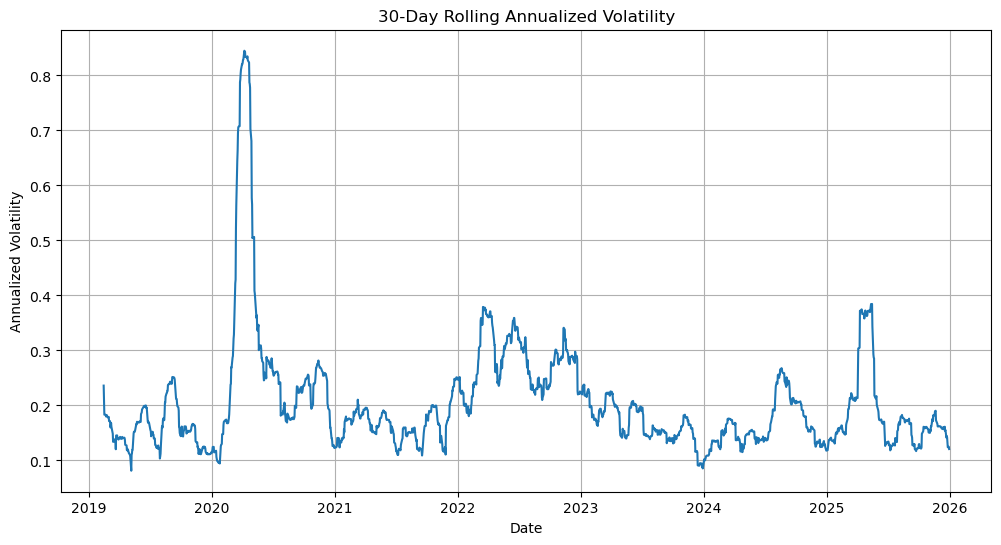

In [34]:
plt.figure(figsize=(12, 6))
plt.plot(rolling_volatility_annualized)
plt.title("30-Day Rolling Annualized Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.show()

# 10. Best and worst trading days

In [35]:

best_day = portfolio_returns.max()
worst_day = portfolio_returns.min()

print(f"Best Day: {best_day:.2%}")
print(f"Worst Day: {worst_day:.2%}")

Best Day: 10.84%
Worst Day: -11.58%


# 11. Positive and negative days

In [36]:

positive_days = (portfolio_returns > 0).sum()
negative_days = (portfolio_returns < 0).sum()

total_days = len(portfolio_returns)

print(f"Positive Days: {positive_days} ({positive_days / total_days:.2%})")
print(f"Negative Days: {negative_days} ({negative_days / total_days:.2%})")

Positive Days: 1017 (56.25%)
Negative Days: 790 (43.69%)


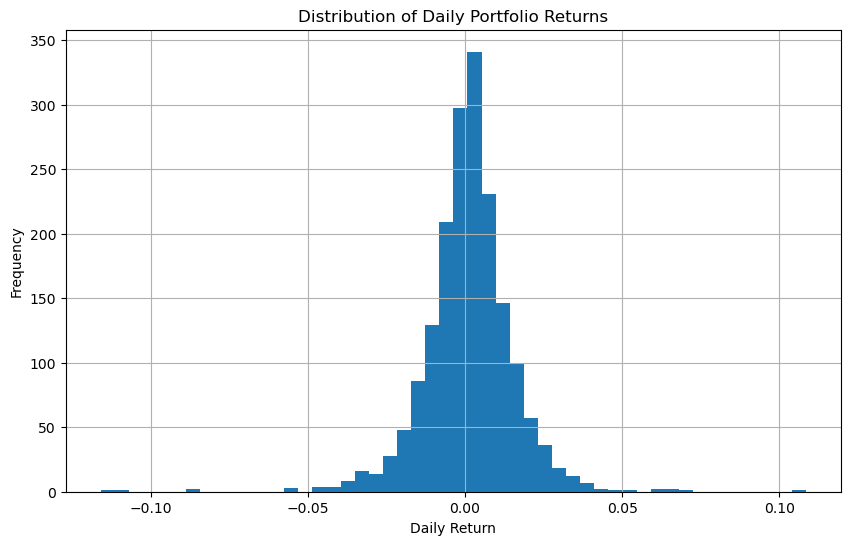

In [62]:
plt.figure(figsize=(10, 6))
plt.hist(portfolio_returns, bins=50)
plt.title("Distribution of Daily Portfolio Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency") #how many trading days fell into each return range.
plt.grid(True)
plt.show()